# Part A  -  Predicting monetary relief

Target: `Closed with monetary relief` vs. every other closed response. Temporal split on narrative complaints: train 2018-22, validate 2023, test on the 2024-25 credit-reporting surge (narrative coverage collapses in 2026, so testing stops at 2025).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from lightgbm import LGBMClassifier
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder

%run ./data_preparation.ipynb

plt.rcParams["figure.figsize"] = (8, 3.5)
SEED = 0
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

### Temporal sample

Closed responses only (`In progress` / `Untimely response` have no outcome yet). A proportional random sample of each window, cached to parquet. Product names are mapped to stable groups across the 2017 and 2023 taxonomy changes (`data_preparation.ipynb`).

In [2]:
SPLIT = {**dict.fromkeys(range(2018, 2023), "train"), 2023: "val", 2024: "test", 2025: "test"}
FRAC = {"train": 0.2, "val": 0.1, "test": 0.05}
SAMPLE = Path("data/part_a_sample.parquet")

if SAMPLE.exists():
    df = pd.read_parquet(SAMPLE)
else:
    meta = read_exports()
    meta["split"] = meta["year"].map(SPLIT)
    ids = pd.concat([g.sample(frac=FRAC[s], random_state=SEED) for s, g in meta.groupby("split")])["Complaint ID"]
    df = read_exports(["Sub-product", "Issue", "Sub-issue", "Company", "State", "Tags", "Consumer complaint narrative"],
                      keep=lambda d: d["Complaint ID"].isin(ids))
    df["split"] = df["year"].map(SPLIT)
    df["text"] = clean(df.pop("Consumer complaint narrative"))
    df = df[df["text"].str.len() > 0].reset_index(drop=True)
    df.to_parquet(SAMPLE, index=False)

df.groupby("split")["y"].agg(n="size", positives="sum", relief_rate="mean").loc[["train", "val", "test"]]

,n,positives,relief_rate
split,,,
train,191186,6983,0.036525
val,48688,1203,0.024708
test,101568,1440,0.014178


In [3]:
# Share of each window by product group: near-zero-relief credit reporting swells in the test years
pd.crosstab(df["product_group"], df["split"], normalize="columns")[["train", "val", "test"]].round(3)

split,train,val,test
product_group,,,
Checking/savings,0.056,0.056,0.039
Credit reporting,0.571,0.715,0.758
Credit/prepaid card,0.084,0.074,0.041
Debt collection,0.147,0.073,0.084
Money transfer,0.028,0.017,0.037
Mortgage,0.062,0.025,0.013
Other,0.000,0.001,0.002
Payday/personal loan,0.013,0.009,0.006
Student loan,0.019,0.013,0.009


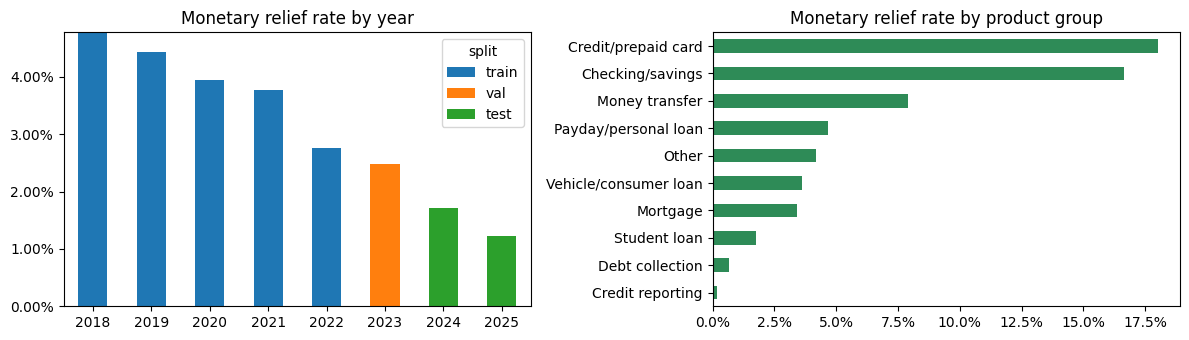

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
df.groupby(["year", "split"])["y"].mean().unstack()[["train", "val", "test"]] \
    .plot.bar(stacked=True, rot=0, ax=axes[0], title="Monetary relief rate by year")
df.groupby("product_group")["y"].mean().sort_values() \
    .plot.barh(ax=axes[1], color="seagreen", title="Monetary relief rate by product group")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].margins(y=0.1)
axes[0].set_xlabel("")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(FIG / "a_relief_rates.png", dpi=150)

### Feature representations

- **Structured**: one-hot product group, sub-product, issue, sub-issue, company, state and tags. `Timely response?` and `Company public response` are recorded with the outcome, so they are left out.
- **TF-IDF**: word uni- and bigrams of the cleaned narrative (top 20k by frequency).
- **Embeddings**: `all-MiniLM-L6-v2` sentence embeddings of the first 256 tokens, cached to `.npy`.

In [5]:
splits = {s: df[df["split"] == s] for s in ["train", "val", "test"]}
y = {s: d["y"].to_numpy() for s, d in splits.items()}

encoders = {
    "structured": (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, dtype=np.float32),
                   lambda d: d[CAT_COLS].fillna("None")),
    "tfidf": (TfidfVectorizer(token_pattern=r"(?u)\b[a-z]{2,}\b", ngram_range=(1, 2), min_df=10, max_df=0.9,
                              max_features=20_000, sublinear_tf=True, dtype=np.float32),
              lambda d: d["text"]),
}
X = {}
for rep, (enc, cols) in encoders.items():
    enc.fit(cols(splits["train"]))
    X[rep] = {s: enc.transform(cols(d)) for s, d in splits.items()}
X["structured+tfidf"] = {s: sp.hstack([X["structured"][s], X["tfidf"][s]]).tocsr() for s in splits}
{rep: m["train"].shape for rep, m in X.items()}

{'structured': (191186, 803),
 'tfidf': (191186, 20000),
 'structured+tfidf': (191186, 20803)}

In [6]:
EMB = Path("data/part_a_embeddings.npy")
if not EMB.exists():
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("all-MiniLM-L6-v2")
    np.save(EMB, st_model.encode(df["text"].tolist(), batch_size=256, normalize_embeddings=True))
emb = np.load(EMB)
X["embedding"] = {s: emb[(df["split"] == s).to_numpy()] for s in splits}
emb.shape

(341442, 384)

### Model grid

Class-weighted logistic regression (L2) and LightGBM on every representation, a small MLP on the embeddings, and a majority-class floor. PR-AUC is the headline metric; F1 uses the threshold that maximizes F1 on the 2023 validation set.

In [7]:
MODELS = {
    "Majority": lambda: DummyClassifier(strategy="prior"),
    "LogReg": lambda: LogisticRegression(C=0.25, class_weight="balanced", max_iter=2000),
    "LightGBM": lambda: LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                       subsample_freq=1, colsample_bytree=0.3, class_weight="balanced",
                                       random_state=SEED, verbose=-1),
    "MLP": lambda: MLPClassifier(hidden_layer_sizes=(256,), early_stopping=True, random_state=SEED),
}
GRID = [("structured", "Majority"), ("structured", "LogReg"), ("structured", "LightGBM"),
        ("tfidf", "LogReg"), ("tfidf", "LightGBM"),
        ("embedding", "LogReg"), ("embedding", "LightGBM"), ("embedding", "MLP"),
        ("structured+tfidf", "LogReg"), ("structured+tfidf", "LightGBM")]


def evaluate(p_val, p_test):
    prec, rec, thr = precision_recall_curve(y["val"], p_val)
    cut = thr[np.argmax((2 * prec * rec / np.maximum(prec + rec, 1e-12))[:-1])]
    return {"val PR-AUC": average_precision_score(y["val"], p_val),
            "test PR-AUC": average_precision_score(y["test"], p_test),
            "test ROC-AUC": roc_auc_score(y["test"], p_test),
            "test F1": f1_score(y["test"], p_test >= cut),
            "test precision@1%": y["test"][np.argsort(-p_test)[:len(p_test) // 100]].mean()}


models, preds, rows = {}, {}, []
for rep, name in GRID:
    models[rep, name] = MODELS[name]().fit(X[rep]["train"], y["train"])
    preds[rep, name] = {s: models[rep, name].predict_proba(X[rep][s])[:, 1] for s in ("val", "test")}
    rows.append({"representation": rep, "model": name, **evaluate(preds[rep, name]["val"], preds[rep, name]["test"])})

results = pd.DataFrame(rows)
results.to_csv(RES / "part_a_results.csv", index=False)
results.round(3)

,representation,model,val PR-AUC,test PR-AUC,test ROC-AUC,test F1,test precision@1%
0,structured,Majority,0.025,0.014,0.500,0.028,0.006
1,structured,LogReg,0.295,0.270,0.966,0.351,0.359
2,structured,LightGBM,0.309,0.280,0.965,0.368,0.323
3,tfidf,LogReg,0.326,0.290,0.966,0.340,0.367
4,tfidf,LightGBM,0.298,0.264,0.959,0.346,0.345
5,embedding,LogReg,0.268,0.243,0.963,0.338,0.312
6,embedding,LightGBM,0.300,0.270,0.965,0.353,0.332
7,embedding,MLP,0.316,0.277,0.967,0.344,0.357
8,structured+tfidf,LogReg,0.365,0.332,0.973,0.383,0.407
9,structured+tfidf,LightGBM,0.324,0.288,0.968,0.362,0.384


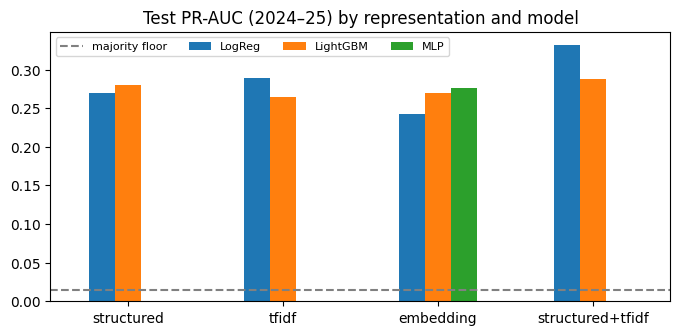

In [8]:
grid = results.pivot(index="representation", columns="model", values="test PR-AUC") \
    .loc[["structured", "tfidf", "embedding", "structured+tfidf"], ["LogReg", "LightGBM", "MLP"]]
ax = grid.plot.bar(rot=0, title="Test PR-AUC (2024–25) by representation and model")
ax.axhline(y["test"].mean(), color="gray", ls="--", label="majority floor")
ax.set_xlabel("")
ax.legend(ncols=4, fontsize=8)
plt.savefig(FIG / "a_pr_auc_grid.png", dpi=150, bbox_inches="tight")

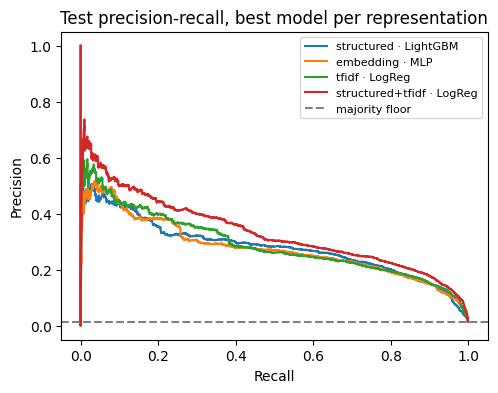

In [9]:
best = results[results["model"] != "Majority"].sort_values("val PR-AUC").groupby("representation").tail(1)
fig, ax = plt.subplots(figsize=(5.5, 4))
for rep, name in zip(best["representation"], best["model"]):
    prec, rec, _ = precision_recall_curve(y["test"], preds[rep, name]["test"])
    ax.plot(rec, prec, label=f"{rep} · {name}")
ax.axhline(y["test"].mean(), color="gray", ls="--", label="majority floor")
ax.set(xlabel="Recall", ylabel="Precision", title="Test precision-recall, best model per representation")
ax.legend(fontsize=8)
fig.savefig(FIG / "a_pr_curves.png", dpi=150, bbox_inches="tight")

### Slices: product and quarter

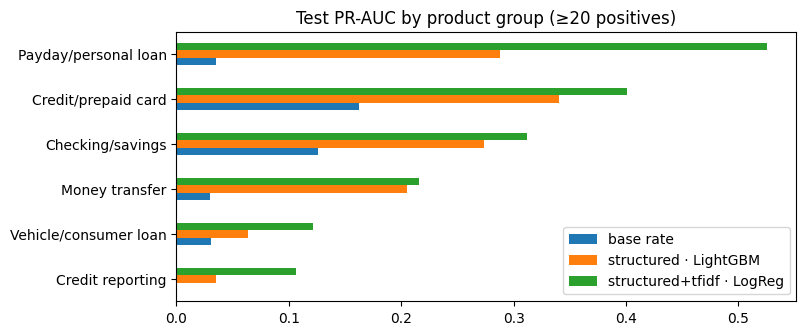

In [10]:
def pr_auc_by(key, p):
    """Test PR-AUC within each group of `key`; groups with fewer than 20 positives are skipped."""
    test = splits["test"].assign(key=np.asarray(key), p=p)
    return test.groupby("key").apply(lambda g: average_precision_score(g["y"], g["p"]) if g["y"].sum() >= 20 else np.nan)


top = best.set_index("representation")["model"]
by_product = pd.DataFrame({"base rate": splits["test"].groupby("product_group")["y"].mean()} |
                          {f"{rep} · {top[rep]}": pr_auc_by(splits["test"]["product_group"], preds[rep, top[rep]]["test"])
                           for rep in ["structured", "structured+tfidf"]}).dropna()
ax = by_product.sort_values(by_product.columns[-1]).plot.barh(title="Test PR-AUC by product group (≥20 positives)")
ax.set_ylabel("")
plt.savefig(FIG / "a_pr_auc_by_product.png", dpi=150, bbox_inches="tight")

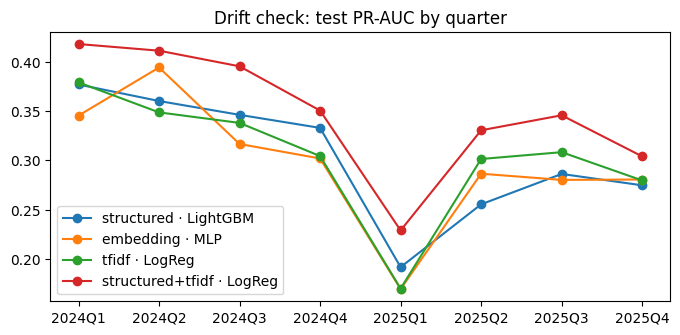

In [11]:
quarter = pd.to_datetime(splits["test"]["Date received"]).dt.to_period("Q").astype(str)
drift = pd.DataFrame({f"{rep} · {name}": pr_auc_by(quarter, preds[rep, name]["test"]) for rep, name in top.items()})
drift.to_csv(RES / "part_a_drift_by_quarter.csv")
ax = drift.plot(marker="o", title="Drift check: test PR-AUC by quarter")
ax.set_xlabel("")
plt.savefig(FIG / "a_drift_by_quarter.png", dpi=150, bbox_inches="tight")

In [12]:
# The 2025Q1 dip: a wave of templated money-transfer complaints (mostly Cash App) that rarely got relief
money = splits["test"].assign(quarter=quarter)[lambda d: d["product_group"] == "Money transfer"]
money.groupby("quarter").agg(complaints=("y", "size"), relief_rate=("y", "mean"),
                             cash_app_share=("Company", lambda c: c.eq("Block, Inc.").mean())).round(3)

,complaints,relief_rate,cash_app_share
quarter,,,
2024Q1,122,0.131,0.139
2024Q2,119,0.076,0.134
2024Q3,104,0.058,0.125
2024Q4,154,0.078,0.130
2025Q1,2465,0.006,0.603
2025Q2,247,0.053,0.393
2025Q3,263,0.080,0.304
2025Q4,310,0.074,0.239


### What carries the signal

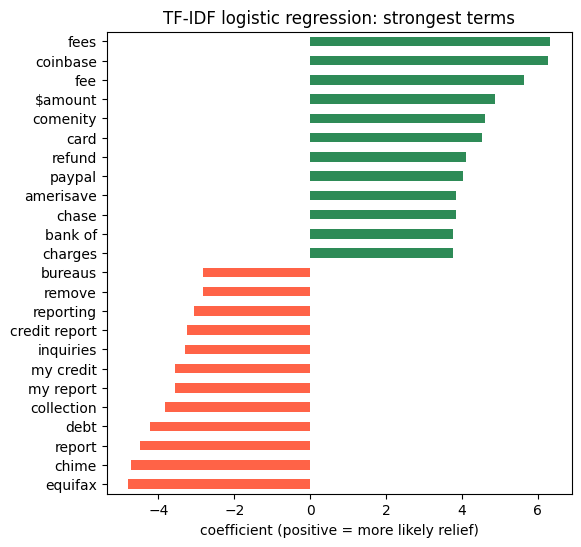

In [13]:
terms = pd.Series(models["tfidf", "LogReg"].coef_[0], index=encoders["tfidf"][0].get_feature_names_out()).sort_values()
top_terms = pd.concat([terms.head(12), terms.tail(12)]).rename(lambda t: t.replace("dollaramount", "$amount"))
ax = top_terms.plot.barh(figsize=(6, 6), color=np.where(top_terms > 0, "seagreen", "tomato"),
                         title="TF-IDF logistic regression: strongest terms")
ax.set_xlabel("coefficient (positive = more likely relief)")
plt.savefig(FIG / "a_top_terms.png", dpi=150, bbox_inches="tight")

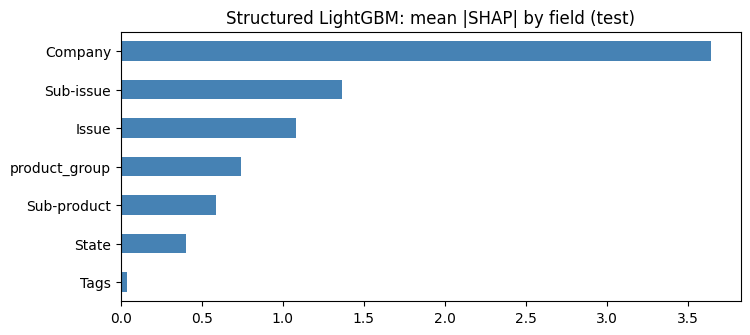

In [14]:
# TreeSHAP contributions from the structured LightGBM, summed over each field's one-hot columns
idx = np.random.default_rng(SEED).choice(len(y["test"]), 5_000, replace=False)
contrib = models["structured", "LightGBM"].predict(X["structured"]["test"][idx], pred_contrib=True)
contrib = np.abs(contrib.toarray() if sp.issparse(contrib) else contrib)[:, :-1].mean(axis=0)
field = [next(c for c in CAT_COLS if n.startswith(c + "_")) for n in encoders["structured"][0].get_feature_names_out()]
ax = pd.Series(contrib, index=field).groupby(level=0).sum().sort_values() \
    .plot.barh(color="steelblue", title="Structured LightGBM: mean |SHAP| by field (test)")
ax.set_ylabel("")
plt.savefig(FIG / "a_shap_fields.png", dpi=150, bbox_inches="tight")

### Takeaways

- Every representation beats the 1.4% majority floor by roughly 20 times  (test PR-AUC 0.24-0.33). Structured + TF-IDF logistic regression is best (0.33), so metadata and text carry complementary signal.
- Linear models win on sparse TF-IDF; the MLP and LightGBM win on dense embeddings.
- Company is the strongest structured field, and the strongest text terms mix *what happened* (fees, refund, charges) with *who it happened with* (Coinbase, PayPal vs. Equifax, Chime).
- PR-AUC falls 0.025-0.04 from validation (2023) to test (2024-25), partly because relief gets rarer (2.5%  to  1.4%). 2025Q1 dips hard: a templated wave of Cash App / Zelle complaints with almost no relief, unlike anything in the 2018-22 training data.
- Further work: near-duplicate handling, rolling calibration, and a fairness audit.

## Validation and feature checks

The next checks use the same training sample. C and the F1 threshold are selected on 2023; five earlier time folds compare the model families.

In [2]:
import gc
import json
import platform
import time

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import TimeSeriesSplit
from threadpoolctl import threadpool_limits

CACHE = Path("artifacts")
CACHE.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})

In [3]:
def log(message):
    print(time.strftime("%H:%M:%S"), message, flush=True)

In [4]:
def savefig(name):
    plt.savefig(FIG / name, dpi=160, bbox_inches="tight", facecolor="white")
    plt.close()

In [5]:
def write_json(name, obj):
    (RES / name).write_text(json.dumps(obj, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v)), encoding="utf-8")

In [6]:
def make_features(train, others):
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, dtype=np.float32)
    vec = TfidfVectorizer(token_pattern=r"(?u)\b[a-z]{2,}\b", ngram_range=(1, 2), min_df=10,
                          max_df=0.9, max_features=20_000, sublinear_tf=True, dtype=np.float32)
    a = ohe.fit_transform(train[CAT_COLS].fillna("None"))
    b = vec.fit_transform(train["text"])
    matrices = [(a, b, sp.hstack([a, b]).tocsr())]
    for d in others:
        a, b = ohe.transform(d[CAT_COLS].fillna("None")), vec.transform(d["text"])
        matrices.append((a, b, sp.hstack([a, b]).tocsr()))
    return ohe, vec, matrices

In [7]:
def lr(c=0.25):
    return LogisticRegression(C=c, class_weight="balanced", max_iter=2000, random_state=SEED)

In [8]:
def tree(leaves=63):
    return LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=leaves, subsample=0.8,
        subsample_freq=1, colsample_bytree=0.3, class_weight="balanced", random_state=SEED, verbose=-1, n_jobs=4)

In [9]:
def supervised():
    log("Loading Part A and fitting train-only feature encoders")
    d = pd.read_parquet("data/part_a_sample.parquet")
    train, val, test = [d[d["split"].eq(s)].copy() for s in ("train", "val", "test")]
    ohe, vec, matrices = make_features(train, [val, test])
    a, v, t = matrices
    yt, yv, ye = [g["y"].to_numpy() for g in (train, val, test)]
    names = np.r_[ohe.get_feature_names_out(), vec.get_feature_names_out()]
    fields = [next(c for c in CAT_COLS if n.startswith(c + "_")) for n in ohe.get_feature_names_out()]
    pd.DataFrame({"index": np.arange(len(names)), "feature": names,
        "field": fields + ["narrative_tfidf"] * len(vec.get_feature_names_out())}).to_csv(RES / "feature_manifest.csv", index=False)
    rows, fitted = [], {}
    for c in [0.01, 0.05, 0.25, 1.0, 4.0]:
        log(f"Logistic regularization C={c}")
        m = lr(c).fit(a[2], yt)
        p = m.predict_proba(v[2])[:, 1]
        rows.append({"C": c, "validation_ap": average_precision_score(yv, p), "iterations": int(m.n_iter_[0])})
        fitted[c] = m
    tuning = pd.DataFrame(rows)
    tuning.to_csv(RES / "a_regularization.csv", index=False)
    best_c = float(tuning.sort_values("validation_ap", ascending=False).iloc[0]["C"])
    model = fitted[best_c]
    pv, pe = model.predict_proba(v[2])[:, 1], model.predict_proba(t[2])[:, 1]
    prec, rec, cuts = precision_recall_curve(yv, pv)
    cut = float(cuts[np.argmax((2 * prec * rec / np.maximum(prec + rec, 1e-12))[:-1])])
    pred = pe >= cut
    summary = {"C": best_c, "threshold": cut, "validation_ap": average_precision_score(yv, pv),
        "test_ap": average_precision_score(ye, pe), "test_roc_auc": roc_auc_score(ye, pe),
        "test_f1": f1_score(ye, pred), "precision": precision_score(ye, pred), "recall": recall_score(ye, pred),
        "confusion_matrix_tn_fp_fn_tp": confusion_matrix(ye, pred).ravel().tolist(), "n_features":len(names)}
    out = test[["Complaint ID", "Date received", "product_group", "Company", "Company response to consumer", "year", "y"]].copy()
    out["score"], out["predicted"] = pe, pred.astype(int)
    out.to_csv(RES / "a_predictions.csv", index=False)
    np.savez_compressed(CACHE / "a_scores.npz", val=pv, test=pe)
    np.save(CACHE / "a_coefficients.npy", model.coef_[0])
    ablation = []
    selections = {"Full metadata + text": np.ones(len(names), dtype=bool),
        "Metadata only": np.arange(len(names)) < a[0].shape[1], "Text only": np.arange(len(names)) >= a[0].shape[1]}
    for field in CAT_COLS:
        selections["Without " + field] = np.array([f != field for f in fields] + [True] * a[1].shape[1])
    for name, mask in selections.items():
        log("Ablation " + name)
        m = model if name == "Full metadata + text" else lr(best_c).fit(a[2][:, mask], yt)
        ablation.append({"features": name, "n_features": int(mask.sum()),
            "validation_ap": average_precision_score(yv, m.predict_proba(v[2][:, mask])[:, 1]),
            "test_ap": average_precision_score(ye, m.predict_proba(t[2][:, mask])[:, 1])})
    abl = pd.DataFrame(ablation)
    abl.to_csv(RES / "a_ablation.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    abl.sort_values("test_ap").plot.barh(x="features", y="test_ap", legend=False, ax=ax, color="steelblue")
    ax.set(xlabel="Test average precision", ylabel="", title="Best logistic model: retraining after removing features")
    savefig("a_ablation.png")
    contrib = np.asarray(abs(t[2]).mean(axis=0)).ravel() * abs(model.coef_[0])
    importance = pd.DataFrame({"feature":names,"coefficient":model.coef_[0],"mean_absolute_contribution":contrib,
        "field": fields + ["narrative_tfidf"] * a[1].shape[1]})
    importance.to_csv(RES / "a_best_feature_importance.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
    importance.groupby("field")["mean_absolute_contribution"].sum().sort_values().plot.barh(ax=axes[0], color="steelblue")
    axes[0].set(xlabel="Mean absolute log-odds contribution", ylabel="", title="Feature groups in the best model")
    terms = importance.iloc[a[0].shape[1]:].sort_values("mean_absolute_contribution").tail(12)
    axes[1].barh(terms["feature"],terms["mean_absolute_contribution"],color=np.where(terms["coefficient"]>0,"seagreen","tomato"))
    axes[1].set(xlabel="Mean absolute log-odds contribution", title="Text terms (green raises score)")
    fig.tight_layout()
    savefig("a_best_importance.png")
    fig, ax = plt.subplots(figsize=(6.5, 2.7))
    ax.semilogx(tuning["C"], tuning["validation_ap"], "o-")
    ax.set(xlabel="C (larger means less regularization)", ylabel="2023 average precision", title="Sensitivity checked on validation, before test")
    savefig("a_sensitivity.png")
    # Platt calibration uses 2023 only. The class-weighted scores are not probabilities.
    def logits(p):
        p = np.clip(p, 1e-7, 1 - 1e-7)
        return np.log(p / (1 - p)).reshape(-1, 1)
    calibrator = LogisticRegression(C=1e6).fit(logits(pv), yv)
    calibrated = calibrator.predict_proba(logits(pe))[:, 1]
    calibration = []
    calibration_points = []
    fig, ax = plt.subplots(figsize=(5.7, 3.3))
    for year in (2024, 2025):
        ok = test["year"].eq(year).to_numpy()
        for name, p in [("Raw weighted score", pe), ("2023 calibrated", calibrated)]:
            observed, predicted = calibration_curve(ye[ok], p[ok], n_bins=8, strategy="quantile")
            calibration_points.extend({"year": year, "method": name, "bin": i, "predicted": x, "observed": z}
                                      for i, (x, z) in enumerate(zip(predicted, observed)))
            ax.plot(predicted, observed, "o-", markersize=3, label=f"{year}, {name}")
            calibration.append({"year":year,"method":name,"brier":brier_score_loss(ye[ok],p[ok]),
                "mean_score":float(p[ok].mean()),"relief_rate":float(ye[ok].mean())})
    ax.plot([0,1],[0,1],color="gray",ls=":")
    ax.set(xlabel="Mean predicted score",ylabel="Observed monetary relief rate", title="Calibration after the training period",
           xlim=(0,0.65),ylim=(0,0.20))
    ax.legend(fontsize=7)
    savefig("a_calibration.png")
    pd.DataFrame(calibration).to_csv(RES / "a_calibration.csv", index=False)
    pd.DataFrame(calibration_points).to_csv(RES / "a_calibration_points.csv", index=False)
    # Fixed validation thresholds and fixed review capacities quantify operational tradeoffs.
    tradeoffs=[]
    for label, threshold in [("Validation max-F1",cut),("Raw score 0.50",0.5)]:
        chosen=pe>=threshold
        tradeoffs.append({"policy":label,"threshold":threshold,"reviewed":int(chosen.sum()),
            "precision":precision_score(ye,chosen,zero_division=0),"recall":recall_score(ye,chosen),"f1":f1_score(ye,chosen)})
    for frac in [0.005,0.01,0.02,0.05]:
        chosen=np.zeros(len(pe),bool);chosen[np.argsort(-pe,kind="stable")[:int(len(pe)*frac)]]=True
        tradeoffs.append({"policy":f"Review top {frac:.1%}","threshold":float(pe[chosen].min()),"reviewed":int(chosen.sum()),
            "precision":precision_score(ye,chosen),"recall":recall_score(ye,chosen),"f1":f1_score(ye,chosen)})
    pd.DataFrame(tradeoffs).to_csv(RES / "a_tradeoffs.csv",index=False)
    # Duplicate audit does not alter the already defined chronological test set.
    norm = d["text"].str.lower().str.replace(r"[^a-z]", "", regex=True)
    hashes = pd.util.hash_pandas_object(norm,index=False)
    old=set(hashes[d["split"].eq("train")])
    overlaps=hashes[d["split"].eq("test")].isin(old).to_numpy()
    unique=~overlaps
    summary.update({"test_matching_training_text":int(overlaps.sum()),"test_ap_without_training_text_matches":
        average_precision_score(ye[unique],pe[unique]),"test_rows":len(test),"test_positives":int(ye.sum())})
    # Save specific errors for a separate, careful text review; truncate output only in the report.
    failed=test.copy();failed["score"],failed["predicted"]=pe,pred.astype(int)
    failed=failed[failed["y"]!=failed["predicted"]]
    failed["error_type"]=np.where(failed["predicted"].eq(1),"false positive","false negative")
    selected=pd.concat([failed[failed["error_type"].eq(kind)].sort_values("score",ascending=(kind=="false negative")).head(12)
                        for kind in ("false positive","false negative")])
    selected.to_json(CACHE / "failure_candidates.json",orient="records",indent=2)
    for col in ["product_group","Company","year"]:
        rows=[]
        for group, g in out.groupby(col):
            if len(g)<100 or g["y"].sum()<20: continue
            rows.append({col:group,"n":len(g),"positives":int(g["y"].sum()),"base_rate":g["y"].mean(),
                "ap":average_precision_score(g["y"],g["score"])})
        pd.DataFrame(rows).to_csv(RES / f"a_slices_{col}.csv",index=False)
    write_json("a_final_summary.json",summary)
    import importlib.metadata
    write_json("environment.json", {"python":platform.python_version(),"platform":platform.platform(),
        **{name:__import__(name).__version__ for name in ["numpy","pandas","scipy","sklearn","lightgbm","matplotlib"]},
        **{name:importlib.metadata.version(name) for name in ["umap-learn","pyarrow","threadpoolctl","numba"]}})
    log("Supervised supplement finished: " + str(summary))

In [10]:
def cv():
    """Five date-blocked expanding folds inside 2018-22; re-fit all learned text features."""
    d=pd.read_parquet("data/part_a_sample.parquet")
    emb=np.load("data/part_a_embeddings.npy",mmap_mode="r")
    dev=d[d["split"].eq("train")].sort_values(["Date received","Complaint ID"])
    dates=np.array(sorted(dev["Date received"].unique()))
    rows=[]
    for fold,(ti,vi) in enumerate(TimeSeriesSplit(n_splits=5).split(dates),1):
        tr=dev[dev["Date received"].isin(dates[ti])]; va=dev[dev["Date received"].isin(dates[vi])]
        log(f"CV fold {fold}: {len(tr):,} train, {len(va):,} validation, ending {dates[vi][-1]}")
        ohe,vec,mat=make_features(tr,[va])
        for name,model,xtrain,xval in [("LogReg",lr(),mat[0][2],mat[1][2]),
                ("LightGBM",tree(),mat[0][2],mat[1][2]),
                ("MLP",MLPClassifier(hidden_layer_sizes=(256,),early_stopping=True,random_state=SEED),emb[tr.index],emb[va.index])]:
            start=time.perf_counter();model.fit(xtrain,tr["y"]);duration=time.perf_counter()-start
            p=model.predict_proba(xval)[:,1]
            rows.append({"fold":fold,"model":name,"representation":"embedding" if name=="MLP" else "structured+tfidf",
                "train_n":len(tr),"validation_n":len(va),"train_end":tr["Date received"].max(),
                "validation_start":va["Date received"].min(),"validation_end":va["Date received"].max(),
                "base_rate":va["y"].mean(),"ap":average_precision_score(va["y"],p),
                "roc_auc":roc_auc_score(va["y"],p),"fit_seconds":duration})
            log(f"{name}: AP {rows[-1]['ap']:.4f}, {duration:.1f}s")
            pd.DataFrame(rows).to_csv(RES / "a_cv_folds.csv",index=False)
        del mat,ohe,vec,xtrain,xval,model
        gc.collect()
    pd.DataFrame(rows).groupby(["model","representation"]).agg(ap_mean=("ap","mean"),ap_sd=("ap","std"),
        roc_auc_mean=("roc_auc","mean"),roc_auc_sd=("roc_auc","std"),mean_fit_seconds=("fit_seconds","mean")).reset_index().to_csv(RES / "a_cv_summary.csv",index=False)

In [11]:
with threadpool_limits(limits=4):
    if not (RES / "a_final_summary.json").exists():
        supervised()
    if not (RES / "a_cv_summary.csv").exists():
        cv()

In [12]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RES = Path('results')
FIG = Path('figures')

def show(name):
    display(pd.read_csv(RES / name))

summary = json.loads((RES / 'a_final_summary.json').read_text())
display(pd.Series(summary, name='Selected logistic model'))

C                                                           0.05
threshold                                               0.823783
validation_ap                                           0.366549
test_ap                                                 0.333619
test_roc_auc                                            0.973788
test_f1                                                 0.378797
precision                                               0.271227
recall                                                  0.627778
confusion_matrix_tn_fp_fn_tp             [97699, 2429, 536, 904]
n_features                                                 20803
test_matching_training_text                                 5023
test_ap_without_training_text_matches                   0.333622
test_rows                                                 101568
test_positives                                              1440
Name: Selected logistic model, dtype: object

## Historical cross-validation

The same five expanding date folds are used for the three original family representatives. All dates in a fold's training set precede the validation dates. Table values use sample standard deviation, not a confidence interval. C is the original 0.25 here; the separate 2023 tuning exercise follows.

In [13]:
folds = pd.read_csv(RES / 'a_cv_folds.csv')
assert len(folds) == 15
assert (folds.train_end < folds.validation_start).all()
display(folds)
show('a_cv_summary.csv')

,fold,model,representation,train_n,validation_n,train_end,validation_start,validation_end,base_rate,ap,roc_auc,fit_seconds
0,1,LogReg,structured+tfidf,20212,19904,2018-11-02,2018-11-03,2019-09-01,0.045418,0.370429,0.927161,0.776323
1,1,LightGBM,structured+tfidf,20212,19904,2018-11-02,2018-11-03,2019-09-01,0.045418,0.320693,0.909008,74.431655
2,1,MLP,embedding,20212,19904,2018-11-02,2018-11-03,2019-09-01,0.045418,0.333275,0.910703,3.447855
3,2,LogReg,structured+tfidf,40116,24711,2019-09-01,2019-09-02,2020-06-30,0.042491,0.372021,0.938618,1.907508
4,2,LightGBM,structured+tfidf,40116,24711,2019-09-01,2019-09-02,2020-06-30,0.042491,0.320786,0.918945,135.434456
5,2,MLP,embedding,40116,24711,2019-09-01,2019-09-02,2020-06-30,0.042491,0.316470,0.916667,10.579322
6,3,LogReg,structured+tfidf,64827,31544,2020-06-30,2020-07-01,2021-04-29,0.039088,0.329879,0.921425,3.061551
7,3,LightGBM,structured+tfidf,64827,31544,2020-06-30,2020-07-01,2021-04-29,0.039088,0.296045,0.910477,202.120762
8,3,MLP,embedding,64827,31544,2020-06-30,2020-07-01,2021-04-29,0.039088,0.312955,0.915873,13.276953
9,4,LogReg,structured+tfidf,96371,35662,2021-04-29,2021-04-30,2022-02-26,0.036117,0.379108,0.949941,4.380860


,model,representation,ap_mean,ap_sd,roc_auc_mean,roc_auc_sd,mean_fit_seconds
0,LightGBM,structured+tfidf,0.320731,0.016135,0.926024,0.019388,183.790655
1,LogReg,structured+tfidf,0.367031,0.021454,0.940288,0.017325,3.434360
2,MLP,embedding,0.327525,0.021661,0.926347,0.016856,13.379357


## Sensitivity and feature removal

Select C on the 2023 validation set. Then retrain the selected model after removing each feature group. The explanation below is for the combined logistic model itself. Large contributions are model associations.

,C,validation_ap,iterations
0,0.01,0.350074,33
1,0.05,0.366549,56
2,0.25,0.365756,100
3,1.00,0.348127,128
4,4.00,0.319582,219


,features,n_features,validation_ap,test_ap
0,Full metadata + text,20803,0.366549,0.333619
1,Metadata only,803,0.300083,0.278256
2,Text only,20000,0.319662,0.283701
3,Without product_group,20794,0.366388,0.334728
4,Without Sub-product,20756,0.366952,0.333587
5,Without Issue,20733,0.365117,0.336628
6,Without Sub-issue,20660,0.371745,0.331567
7,Without Company,20331,0.341254,0.306390
8,Without State,20745,0.366276,0.333636
9,Without Tags,20799,0.365866,0.333262


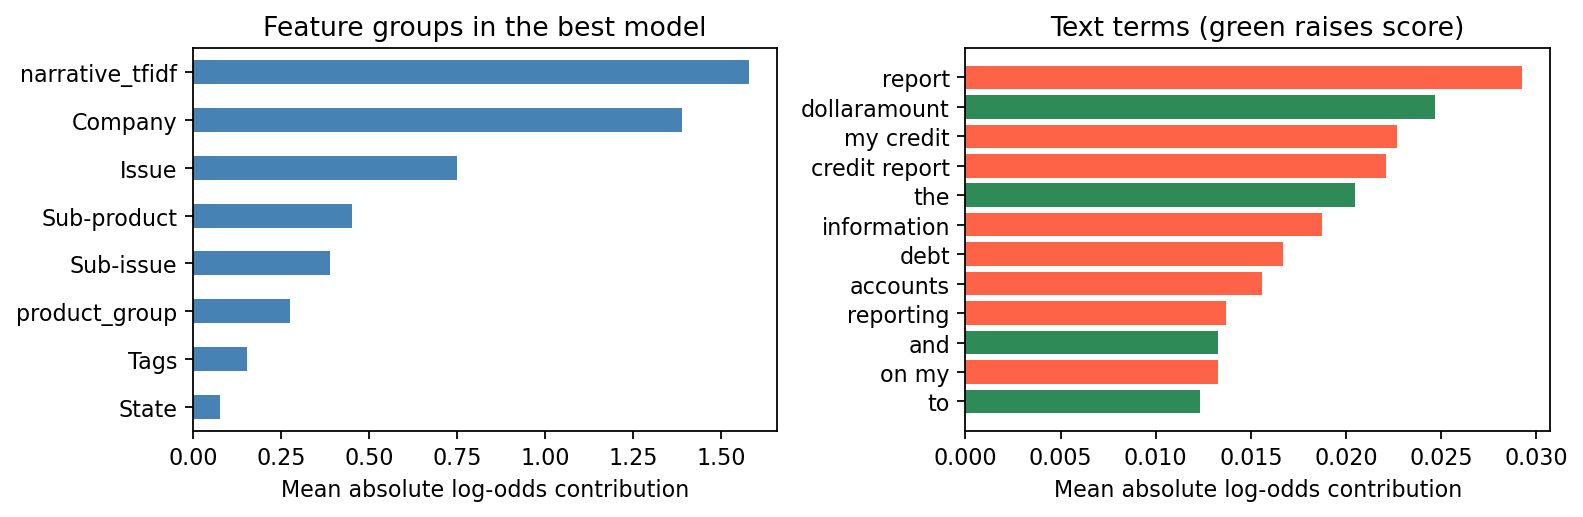

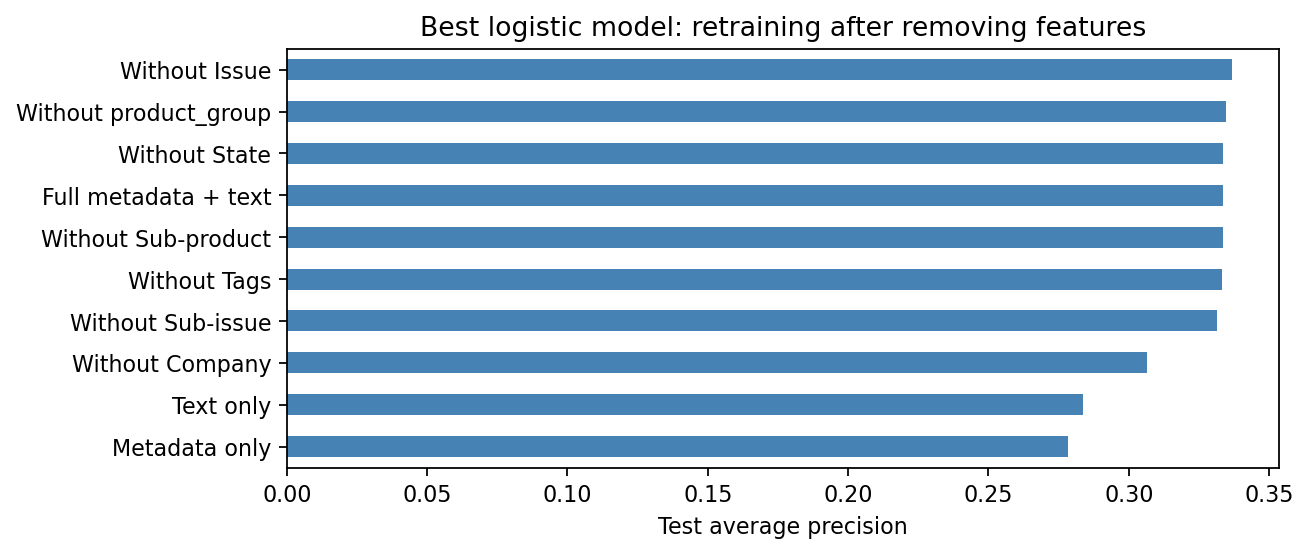

In [14]:
show('a_regularization.csv')
show('a_ablation.csv')
display(Image(filename=str(FIG / 'a_best_importance.png')))
display(Image(filename=str(FIG / 'a_ablation.png')))

## Calibration and review capacity

The log-odds mapping is fitted using 2023 only. Raw weighted scores should not be described as probabilities. Fixed review capacities offer a different tradeoff from maximizing validation F1.

,year,method,brier,mean_score,relief_rate
0,2024,Raw weighted score,0.042508,0.090354,0.017089
1,2024,2023 calibrated,0.012565,0.016084,0.017089
2,2025,Raw weighted score,0.043508,0.087876,0.012229
3,2025,2023 calibrated,0.009946,0.015039,0.012229


,policy,threshold,reviewed,precision,recall,f1
0,Validation max-F1,0.823783,3333,0.271227,0.627778,0.378797
1,Raw score 0.50,0.500000,7378,0.175793,0.900694,0.294171
2,Review top 0.5%,0.949017,507,0.475345,0.167361,0.247560
3,Review top 1.0%,0.924071,1015,0.402956,0.284028,0.333198
4,Review top 2.0%,0.887171,2031,0.320039,0.451389,0.374532
5,Review top 5.0%,0.708185,5078,0.225286,0.794444,0.351028


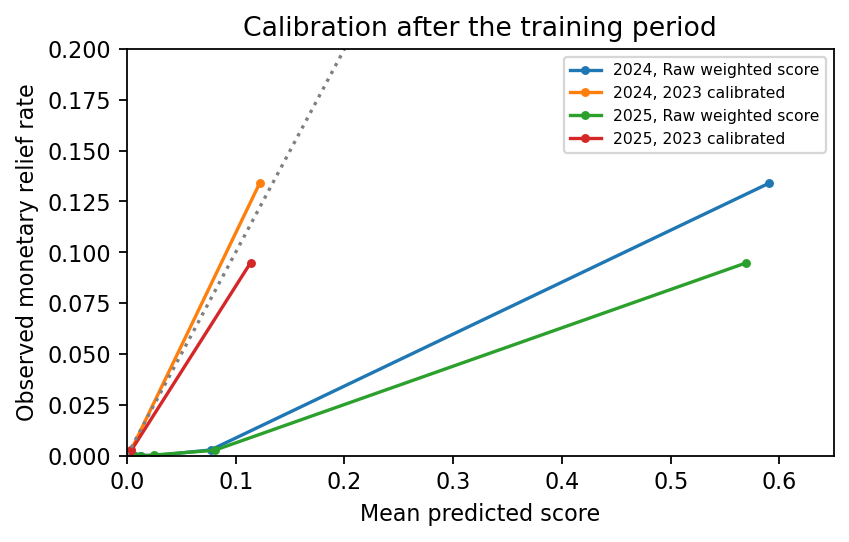

In [15]:
show('a_calibration.csv')
show('a_tradeoffs.csv')
display(Image(filename=str(FIG / 'a_calibration.png')))

## Three specific failures

These are real held-out records. Descriptions are paraphrased to avoid repeating extra personal details. Possible explanations are hypotheses, not known causes of the company's response.

In [16]:
failures = json.loads((RES / 'failure_analysis.json').read_text())
for case in failures:
    display(Markdown('**Complaint ' + case['Complaint ID'] + ': ' + case['category'] + '**'))
    display(pd.Series(case))

**Complaint 12230857: Earlier refund confused with the final outcome**

Complaint ID                                                12230857
date                                                      2025-02-26
product                                             Checking/savings
outcome                                      Closed with explanation
score                                                       0.990139
error_type                                            false positive
category              Earlier refund confused with the final outcome
description        The narrative describes one overdraft fee and ...
possible_reason    Words about refunds and fees resemble successf...
improvement        An event-order representation could separate p...
dtype: object

**Complaint 16791143: Too little information in the narrative**

Complaint ID                                                16791143
date                                                      2025-10-23
product                                               Money transfer
outcome                                  Closed with monetary relief
score                                                       0.022567
error_type                                            false negative
category                     Too little information in the narrative
description        The cleaned text is only a short fragment nami...
possible_reason    There is almost no detail about the transactio...
improvement        A model could flag low-information text for hu...
dtype: object

**Complaint 11405369: Product label hides a different financial issue**

Complaint ID                                                11405369
date                                                      2025-01-06
product                                             Credit reporting
outcome                                  Closed with monetary relief
score                                                       0.001693
error_type                                            false negative
category             Product label hides a different financial issue
description        The record is labeled credit reporting, but th...
possible_reason    The credit-reporting category usually has litt...
improvement        A multi-issue text representation could distin...
dtype: object

## Quarterly performance

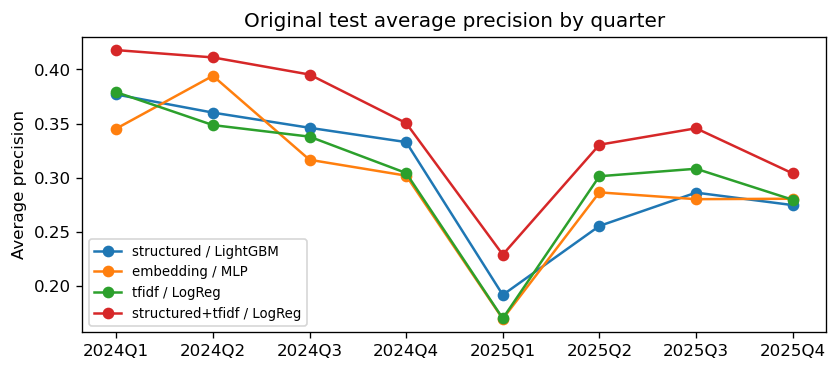

In [17]:
drift_plot = pd.read_csv(RES / "part_a_drift_by_quarter.csv").set_index("key")
drift_plot.columns = [c.replace("\u00b7", "/") for c in drift_plot.columns]
ax = drift_plot.plot(marker="o", figsize=(8, 3.2),
                     title="Original test average precision by quarter")
ax.set(xlabel="", ylabel="Average precision")
ax.legend(fontsize=8)
plt.savefig(FIG / "a_drift_by_quarter.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

### Plots

Redraw the saved results with larger labels and lossless images.

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

FIG = Path("figures")
RES = Path("results")
plt.rcParams.update({
    "font.family": "Arial", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "figure.dpi": 120,
    "savefig.dpi": 600, "axes.spines.top": False,
    "axes.spines.right": False,
})



In [3]:
def save_figure(fig, name):
    fig.savefig(FIG / name, dpi=600, bbox_inches="tight", pad_inches=0.06, facecolor="white")
    plt.close(fig)

In [4]:
def supervised_figures():
    importance = pd.read_csv(RES / "a_best_feature_importance.csv")
    groups = importance.groupby("field").mean_absolute_contribution.sum().sort_values()
    groups = groups.rename(index={"narrative_tfidf": "Narrative TF-IDF", "product_group": "Product group"})
    terms = importance[importance.field.eq("narrative_tfidf")].nlargest(10, "mean_absolute_contribution").iloc[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 2.45))
    axes[0].barh(groups.index, groups.values, color="steelblue")
    axes[0].set(title="Feature groups", xlabel="Mean absolute contribution")
    axes[1].barh(terms.feature.str.replace("dollaramount", "amount", regex=False), terms.mean_absolute_contribution,
                 color=np.where(terms.coefficient.gt(0), "seagreen", "tomato"))
    axes[1].set(title="Text terms (green raises score)", xlabel="Mean absolute contribution")
    axes[0].tick_params(axis="y", labelsize=9.5)
    axes[1].tick_params(axis="y", labelsize=9.5)
    fig.tight_layout(w_pad=1.2)
    save_figure(fig, "a_best_importance.png")

    ablation = pd.read_csv(RES / "a_ablation.csv").sort_values("test_ap")
    fig, ax = plt.subplots(figsize=(7.1, 2.55))
    colors = ["#24618b" if name == "Full metadata + text" else "#77a6c5" for name in ablation.features]
    bars = ax.barh(ablation.features, ablation.test_ap, color=colors)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set(xlabel="Test average precision", xlim=(0, 0.375), title="Feature removal and retraining")
    ax.tick_params(axis="y", labelsize=9.5)
    fig.tight_layout()
    save_figure(fig, "a_ablation.png")

    tuning = pd.read_csv(RES / "a_regularization.csv")
    fig, ax = plt.subplots(figsize=(7.1, 1.7))
    ax.plot(tuning.C, tuning.validation_ap, "o-", color="steelblue", markersize=4)
    ax.set(xscale="log", xlabel="C (larger means less regularization)", ylabel="Validation AP",
           title="Regularization sensitivity")
    ax.set_xticks(tuning.C, [f"{c:g}" for c in tuning.C])
    ax.minorticks_off()
    fig.tight_layout()
    save_figure(fig, "a_sensitivity.png")

    points = pd.read_csv(RES / "a_calibration_points.csv")
    fig, ax = plt.subplots(figsize=(7.1, 2.05))
    colors = {2024: "#24618b", 2025: "#d2691e"}
    for (year, method), frame in points.groupby(["year", "method"], sort=False):
        calibrated = method == "2023 calibrated"
        ax.plot(frame.predicted, frame.observed, marker="o", markersize=3, color=colors[year],
                ls="-" if calibrated else "--", label=f"{year}, {'calibrated' if calibrated else 'raw'}")
    ax.plot([0, 0.2], [0, 0.2], color="gray", ls=":", label="Perfect calibration")
    ax.set(xlim=(0, 0.65), ylim=(0, 0.2), xlabel="Mean predicted score", ylabel="Observed relief rate",
           title="Calibration in the two test years")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(loc="upper right", ncol=2, fontsize=8.5, frameon=False)
    fig.tight_layout()
    save_figure(fig, "a_calibration.png")

    drift = pd.read_csv(RES / "part_a_drift_by_quarter.csv").set_index("key")
    names = ["Metadata / LightGBM", "Embeddings / MLP", "Text / logistic", "Metadata + text / logistic"]
    fig, ax = plt.subplots(figsize=(7.1, 2.25))
    for column, label in zip(drift, names):
        ax.plot(drift.index, drift[column], marker="o", markersize=3, label=label)
    ax.set(xlabel="", ylabel="Average precision", title="Performance by quarter", ylim=(0.14, 0.48))
    ax.legend(loc="upper right", ncol=2, fontsize=8, frameon=False)
    fig.tight_layout()
    save_figure(fig, "a_drift_by_quarter.png")

In [5]:
supervised_figures()